In [9]:
CUDA_VISIBLE_DEVICES=1
import numpy as np
import matplotlib.pyplot as plt
import os


In [10]:
# Define the absolute paths to the results files
# Example: "/home/ivan/repos/TF4OT/experiments/.../eval_all_pairs_1d_sqeuclidean_results_tot.npy"
PATH_TOT = "/home/ivan/repos/TF4OT/experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_sqeuclidean/eval_all_pairs_1d_sqeuclidean_results_tot.npy" 
PATH_NOT = "/home/ivan/repos/TF4OT/experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_sqeuclidean/eval_all_pairs_1d_sqeuclidean_results_not.npy"

In [ ]:

def load_results(path_tot, path_not):
    if not os.path.exists(path_tot):
        print(f"Error: File not found: {path_tot}")
        return None, None
    if not os.path.exists(path_not):
        print(f"Error: File not found: {path_not}")
        return None, None
        
    print(f"Loading {path_tot}...")
    data_tot = np.load(path_tot, allow_pickle=True)
    print(f"Loading {path_not}...")
    data_not = np.load(path_not, allow_pickle=True)
    
    return data_tot, data_not

data_tot, data_not = load_results(PATH_TOT, PATH_NOT)

def extract_metrics(data_array):
    if data_array is None: return {}
    
    metrics = {
        'MAE': [],
        'MAPE': [],
        'Hellinger': [],
        'OT Cost Diff': [],
        'Total Variation': [],
        'Run Time (Seconds)': []
    }
    
    for item in data_array:
        # Dictionary keys from run_inference.py
        if 'mae_sparse' in item: metrics['MAE'].append(item['mae_sparse'])
        if 'mape_sparse' in item: metrics['MAPE'].append(item['mape_sparse'])
        if 'hellinger_sparse' in item: metrics['Hellinger'].append(item['hellinger_sparse'])
        if 'otcost_diff' in item: metrics['OT Cost Diff'].append(item['otcost_diff'])
        if 'tv_sparse' in item: metrics['Total Variation'].append(item['tv_sparse'])
        if 'run_time' in item: metrics['Run Time (Seconds)'].append(item['run_time'])
            
    return metrics

metrics_tot = extract_metrics(data_tot)
metrics_not = extract_metrics(data_not)

print(f"Metrics extracted. TOT items: {len(metrics_tot['MAE'])}, NOT items: {len(metrics_not['MAE'])}")

Loading /home/ivan/repos/TF4OT/experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_sqeuclidean/eval_all_pairs_1d_sqeuclidean_results_tot.npy...
Loading /home/ivan/repos/TF4OT/experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_sqeuclidean/eval_all_pairs_1d_sqeuclidean_results_not.npy...
Metrics extracted. TOT items: 144, NOT items: 144


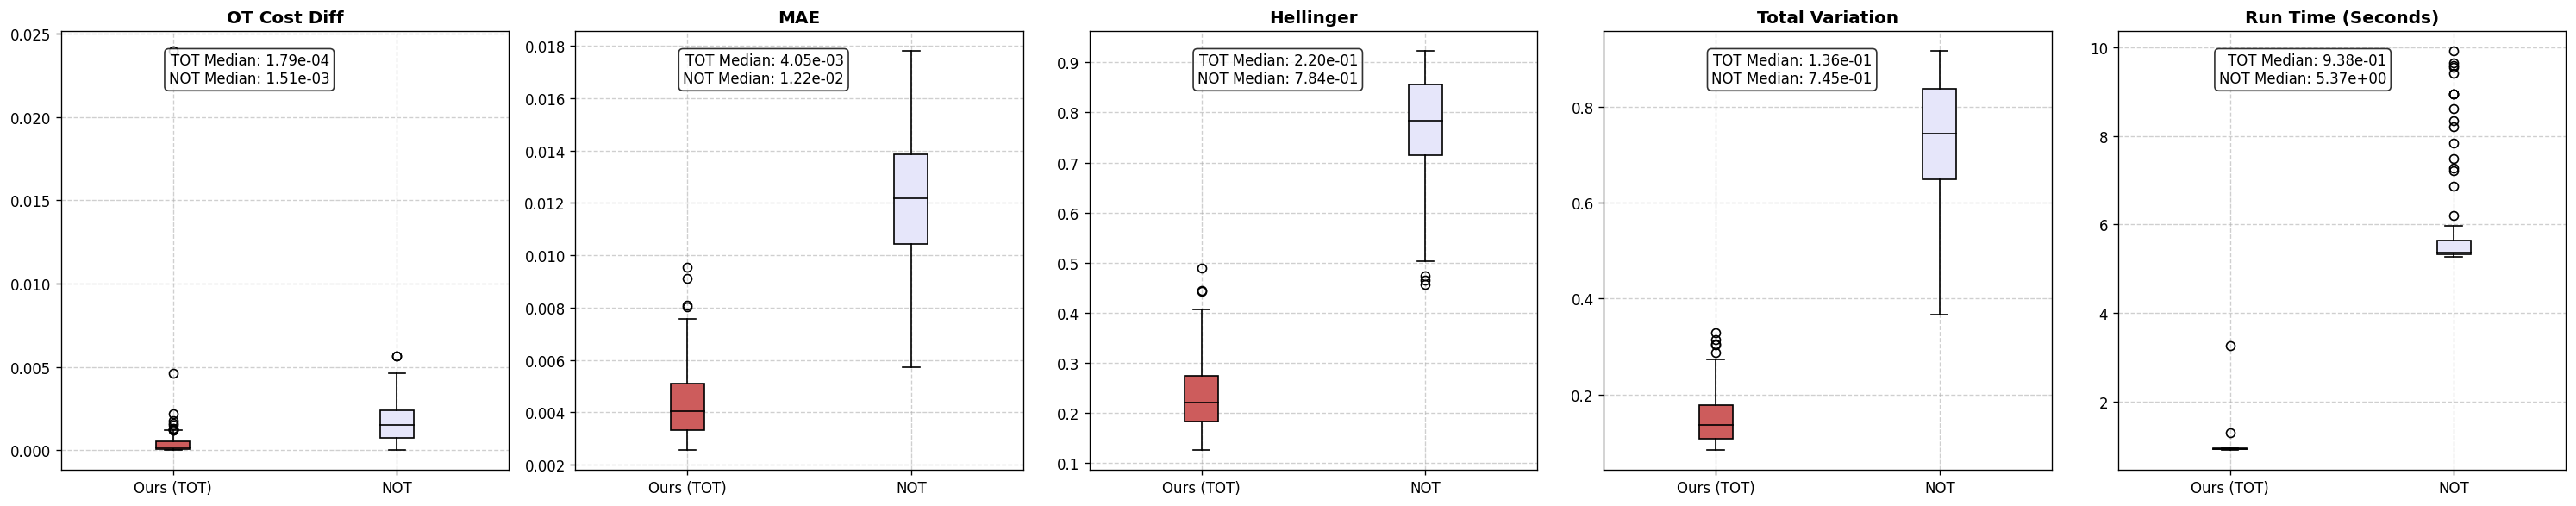

In [ ]:

def plot_comparison(metrics_tot, metrics_not):
    # Metrics to plot
    keys = ['OT Cost Diff', 'MAE', 'Hellinger', 'Total Variation', 'Run Time (Seconds)']
    
    if not metrics_tot or not metrics_not:
        print("No data to plot.")
        return

    # Style: Matches TF4OT/run_inference.py
    # Increased width for 5 plots
    fig, axes = plt.subplots(1, 5, figsize=(25, 5), dpi=120)
    
    for i, key in enumerate(keys):
        ax = axes[i]
        
        val_tot = metrics_tot.get(key, [])
        val_not = metrics_not.get(key, [])
        
        plot_data = []
        labels = []
        colors = []
        
        # We assume both have data if keys exist, filtering NaNs
        val_tot = [v for v in val_tot if not np.isnan(v)]
        val_not = [v for v in val_not if not np.isnan(v)]
        
        if len(val_tot) > 0:
            plot_data.append(val_tot)
            labels.append('Ours (TOT)')
            colors.append('indianred')
            
        if len(val_not) > 0:
            plot_data.append(val_not)
            labels.append('NOT')
            colors.append('lavender')
            
        if not plot_data:
            continue
            
        bplot = ax.boxplot(plot_data, vert=True, patch_artist=True, labels=labels,
                           medianprops=dict(color="black"))
        
        # Color boxes
        for patch, color in zip(bplot['boxes'], colors):
            patch.set_facecolor(color)
            
        ax.set_title(key, fontsize=12, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.6)
        
        # Add basic stats text
        m_median_tot = np.median(val_tot) if len(val_tot) > 0 else 0
        m_median_not = np.median(val_not) if len(val_not) > 0 else 0
        stats_text = f"TOT Median: {m_median_tot:.2e}\nNOT Median: {m_median_not:.2e}"
        ax.text(0.6, 0.95, stats_text, 
                    transform=ax.transAxes, verticalalignment='top', horizontalalignment='right',
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, pad=0.3))
        
    plt.tight_layout()
    plt.show()

plot_comparison(metrics_tot, metrics_not)